Bài 5: Biểu diễn bài toán n quân hậu

In [10]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your working directory is now Google Drive: My Drive > Colab Notebooks


1. Mục tiêu bài toán:

Bài toán N quân hậu yêu cầu đặt n quân hậu lên bàn cờ kích thước n x n sao cho không có hai quân hậu nào tấn công nhau.

Trong cờ vua, quân hậu có thể di chuyển theo hàng ngang, cột dọc và đường chéo. Vì vậy, ta cần sắp xếp các quân hậu sao cho không có hai quân nào nằm cùng hàng hoặc cùng đường chéo.

Để đơn giản hóa việc biểu diễn, ta quy ước mỗi cột chỉ có đúng một quân hậu. Nhờ đó, ta không cần kiểm tra các quân hậu có nằm cùng cột hay không, vì điều kiện này đã được đảm bảo ngay từ cách biểu diễn trạng thái.

2. Biểu diễn trạng thái bàn cờ:

Ta biểu diễn một bàn cờ bằng một danh sách hoặc mảng board có n phần tử:

board = [ro, r1, ... , rn-1]

Trong đó:

- len(board) = n : bàn cờ có n cột và n quân hậu.
- board[i] là chỉ số hàng của quân hậu nằm tại cột i.
- Chỉ số hàng và cột được đánh số từ 0 đến n - 1.
- Mỗi phần tử có giá trị từ 0 đến n - 1.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)

def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    n = len(board)
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""
    n = len(board)
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

3. Khảo sát các hàm

Trong file n_queens. ipynb, phần Helper functions đã cung cấp ba hàm chính và một
hàm hỗ trợ tính số tổ hợp.

3.1. Hàm random board(n)

Chức năng: Tạo ngẫu nhiên một bàn cờ kích thước n x n.

Hàm trả về một mảng có n phần tử, trong đó mỗi phần tử là chỉ số hàng của quân hậu tại cột tương ứng. Các giá trị được chọn ngẫu nhiên từ 0 đến n-1.

Kết quả thực tế có thể khác nhau tùy vào trạng thái sinh số ngẫu nhiên. Hàm này đảm bảo mỗi cột có đúng một quân hậu, nhưng không đảm bảo các quân hậu không tấn công nhau.

3.2. Hàm conflicts(board)

Hàm comb2(n) tính số cặp có thể chọn từ n phần tử:
nC2 = (n(n-1)) / 2

Tiếp theo, hàm conflicts(board) sử dụng kết quả này để tính số cặp quân hậu xung đột.

Hàm conflicts(board) đếm số quân hậu nằm cùng hàng và cùng các đường chéo. Vì mỗi cột đã có đúng một quân hậu nên không cần đếm xung đột theo cột.

3.3. Hàm show_board(board)

Chức năng: Hiển thị bàn cờ dưới dạng hình ảnh, trong đó các ô được tô màu xen kẽ và quân hậu được biểu diễn bằng ký hiệu ♛.

Ngoài việc vẽ bàn cờ, hàm còn in ra số xung đột của trạng thái hiện tại.

4. Xây dựng hàm mục tiêu h(board)

Hàm mục tiêu được định nghĩa là số cặp quân hậu có thể tấn công nhau:

h(board) = số cặp quân hậu cùng hàng hoặc cùng đường chéo

Giả sử quân hậu thứ i nằm tại vị trí (board[i],i), quân hậu thứ j nằm tại vị trí (board[j],j).

Hai quân hậu tấn công nhau khi thỏa mãn ít nhất một trong hai điều kiện:
- Cùng hàng: board[i] = board[j].
- Cùng đường chéo: |board[i] - board[j]| = |i-j|.
Do mỗi cột chỉ có một quân hậu nên ta chỉ cần kiểm tra các cặp quân hậu có chỉ số i<j.

In [15]:
def h(board):
    n = len(board)
    conflicts = 0

    for i in range(n):
        for j in range(i + 1, n):
            # Hai quân hậu cùng hàng
            same_row = board[i] == board[j]

            # Hai quân hậu cùng đường chéo
            same_diagonal = abs(board[i] - board[j]) == abs(i - j)

            if same_row or same_diagonal:
                conflicts += 1

    return conflicts

Giải thích:
1. n = len(board) xác định số quân hậu.
2. Hai vòng lặp duyệt qua từng cặp quân hậu khác nhau.
3. same_row kiểm tra hai quân hậu có cùng hàng hay không.
4. same_diagonal kiểm tra khoảng cách hàng có bằng khoảng cách cột hay không.
5. Nếu một trong hai điều kiện đúng, biến conflicts tăng thêm 1.
6. Hàm trả về tổng số cặp quân hậu xung đột.

5. Tạo bàn cờ với n=4 và n=8

5.1. Tạo bàn cờ 4 x 4

Board with 4 conflicts.


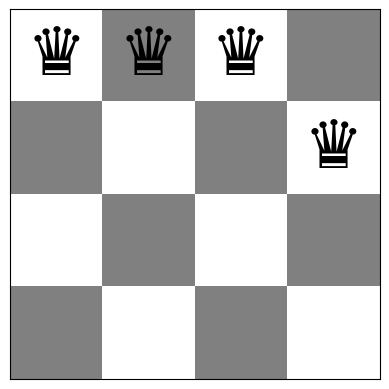

Queens (left to right) are at rows: [0 0 0 1]
Number of conflicts: 4


In [13]:
board = random_board(4)
show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

Board with 0 conflicts.


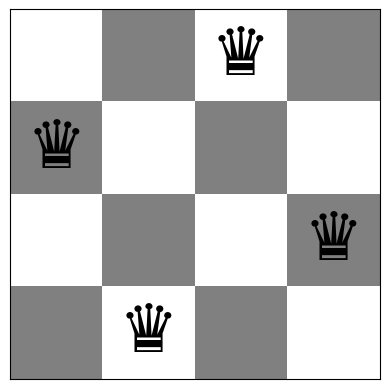

In [16]:
board = [1,3,0,2]
show_board(board)

Như vậy, bốn quân hậu lần lượt nằm tại các vị trí (1,0), (3,1), (0,2), (2,3), theo thứ tự (hàng, cột).

Board with 0 conflicts.


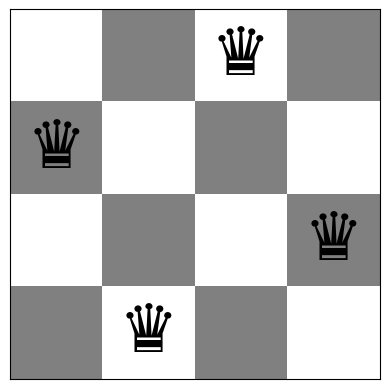

Bàn cờ: [1, 3, 0, 2]
h(board) = 0
conflicts(board) = 0


In [19]:
board4 = [1, 3, 0, 2]
show_board(board4)

print("Bàn cờ:", board4)
print("h(board) =", h(board4))
print("conflicts(board) =", conflicts(board4))

Nhận xét: Bàn cờ có bốn quân hậu, mỗi cột có đúng một quân hậu. Không có hai quân hậu nào cùng hàng hoặc cùng đường chéo nên h(board) = 0. Đây là một lời giải hợp lệ cho bài toán 4 quân hậu.

5.2. Tạo bàn cờ 8 x 8

Đối với bàn cờ 8 x 8, ta sử dụng hàm random_board(8) để tạo một trạng thái ngẫu nhiên. Đồng thời, có thể sử dụng một trạng thái đã biết là lời giải để kiểm tra hàm mục tiêu.

Board with 6 conflicts.


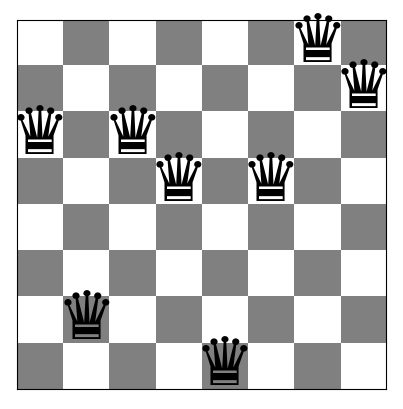

Bàn cờ ngẫu nhiên: [2 6 2 3 7 3 0 1]
h(board) = 6
conflicts(board) = 6
Board with 0 conflicts.


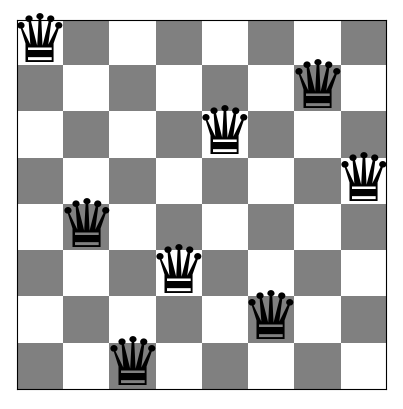

Bàn cờ lời giải: [0, 4, 7, 5, 2, 6, 1, 3]
h(board) = 0
conflicts(board) = 0


In [22]:
# Tạo bàn cờ 8x8 ngẫu nhiên
board8_random = random_board(8)
show_board(board8_random)

print("Bàn cờ ngẫu nhiên:", board8_random)
print("h(board) =", h(board8_random))
print("conflicts(board) =", conflicts(board8_random))


# Một lời giải hợp lệ cho bài toán 8 quân hậu
board8_solution = [0, 4, 7, 5, 2, 6, 1, 3]
show_board(board8_solution)

print("Bàn cờ lời giải:", board8_solution)
print("h(board) =", h(board8_solution))
print("conflicts(board) =", conflicts(board8_solution))

Đối với bàn cờ ngẫu nhiên, giá trị h(board) có thể bằng 0 hoặc lớn hơn 0, tùy vào cách sắp xếp các quân hậu.

6. Kiểm tra điều kiện h(board) = 0

In [23]:
def is_solution(board):
    n = len(board)

    # Kiểm tra giá trị hàng có hợp lệ không
    if any(row < 0 or row >= n for row in board):
        return False

    # Kiểm tra từng cặp quân hậu
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j]:
                return False

            if abs(board[i] - board[j]) == abs(i - j):
                return False

    return True

# Kiểm tra bàn cờ mẫu
boards = [
    [1, 3, 0, 2],
    [0, 4, 7, 5, 2, 6, 1, 3],
    random_board(4),
    random_board(8)
]

for board in boards:
    print("Bàn cờ:", board)
    print("h(board) =", h(board))
    print("Lời giải hợp lệ:", is_solution(board))
    print("Kiểm tra điều kiện:", (h(board) == 0) == is_solution(board))
    print("-" * 40)

Bàn cờ: [1, 3, 0, 2]
h(board) = 0
Lời giải hợp lệ: True
Kiểm tra điều kiện: True
----------------------------------------
Bàn cờ: [0, 4, 7, 5, 2, 6, 1, 3]
h(board) = 0
Lời giải hợp lệ: True
Kiểm tra điều kiện: True
----------------------------------------
Bàn cờ: [3 0 3 2]
h(board) = 3
Lời giải hợp lệ: False
Kiểm tra điều kiện: True
----------------------------------------
Bàn cờ: [3 4 1 3 3 3 2 1]
h(board) = 13
Lời giải hợp lệ: False
Kiểm tra điều kiện: True
----------------------------------------


Bài 6: Các biến thể Hill Climbing

Task 1 — Steepest-ascent Hill Climbing


Board with 1 conflicts.


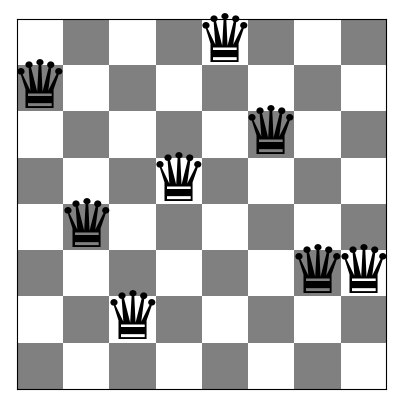

Bàn cờ cuối: [1 4 6 3 0 2 5 5]
Số xung đột cuối: 1
Số bước: 4
Số lần đánh giá: 280
Mắc kẹt tại cực tiểu cục bộ: True


In [25]:

def steepest_hill_climbing(board):
    board = np.array(board, dtype=int).copy()
    n = len(board)
    steps = 0
    evaluations = 0
    history = [conflicts(board)]

    while True:
        current_h = conflicts(board)
        best_board = None
        best_h = current_h
        # Duyệt tất cả nước đi lân cận
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue

                neighbor = board.copy()
                neighbor[col] = row
                neighbor_h = conflicts(neighbor)
                evaluations += 1
                # Chỉ giữ nước đi tốt hơn trạng thái hiện tại
                if neighbor_h < best_h:
                    best_h = neighbor_h
                    best_board = neighbor.copy()

        # Không còn nước đi cải thiện
        if best_board is None:
            break

        board = best_board
        steps += 1
        history.append(best_h)

    final_h = conflicts(board)

    return {
        "board": board,
        "conflicts": final_h,
        "steps": steps,
        "evaluations": evaluations,
        "local_optimum": final_h > 0,
        "plateau": final_h > 0,
        "history": history
    }

# Thử nghiệm với bàn cờ 8 quân hậu
result1 = steepest_hill_climbing(random_board(8))
show_board(result1["board"])
print("Bàn cờ cuối:", result1["board"])
print("Số xung đột cuối:", result1["conflicts"])
print("Số bước:", result1["steps"])
print("Số lần đánh giá:", result1["evaluations"])
print("Mắc kẹt tại cực tiểu cục bộ:", result1["local_optimum"])


Task 2 — Inefficient Stochastic Hill Climbing


Board with 2 conflicts.


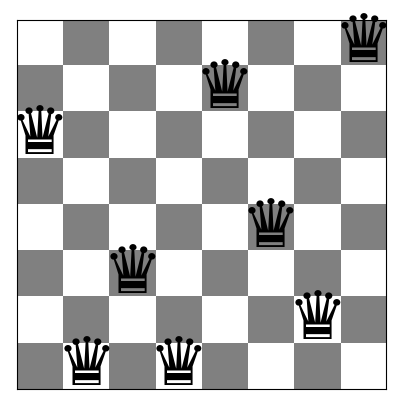

Bàn cờ cuối: [2 7 5 7 1 4 6 0]
Số xung đột cuối: 2
Số bước: 3
Số lần đánh giá: 224
Mắc kẹt tại cực tiểu cục bộ: True


In [26]:

def inefficient_stochastic_hill_climbing(board):
    board = np.array(board, dtype=int).copy()
    n = len(board)
    steps = 0
    evaluations = 0
    history = [conflicts(board)]

    while True:
        current_h = conflicts(board)
        improving_moves = []
        # Đánh giá toàn bộ nước đi lân cận
        for col in range(n):
            for row in range(n):
                if row == board[col]:
                    continue

                neighbor = board.copy()
                neighbor[col] = row
                neighbor_h = conflicts(neighbor)
                evaluations += 1
                if neighbor_h < current_h:
                    improving_moves.append((neighbor, neighbor_h))

        # Không có nước đi cải thiện thì dừng
        if len(improving_moves) == 0:
            break

        # Chọn ngẫu nhiên một nước đi cải thiện
        selected = np.random.randint(len(improving_moves))
        board = improving_moves[selected][0]
        steps += 1
        history.append(conflicts(board))

    final_h = conflicts(board)

    return {
        "board": board,
        "conflicts": final_h,
        "steps": steps,
        "evaluations": evaluations,
        "local_optimum": final_h > 0,
        "plateau": final_h > 0,
        "history": history
    }


# Thử nghiệm với bàn cờ 8 quân hậu
result2 = inefficient_stochastic_hill_climbing(random_board(8))
show_board(result2["board"])
print("Bàn cờ cuối:", result2["board"])
print("Số xung đột cuối:", result2["conflicts"])
print("Số bước:", result2["steps"])
print("Số lần đánh giá:", result2["evaluations"])
print("Mắc kẹt tại cực tiểu cục bộ:", result2["local_optimum"])


Task 3 — Efficient Stochastic Hill Climbing

Board with 1 conflicts.


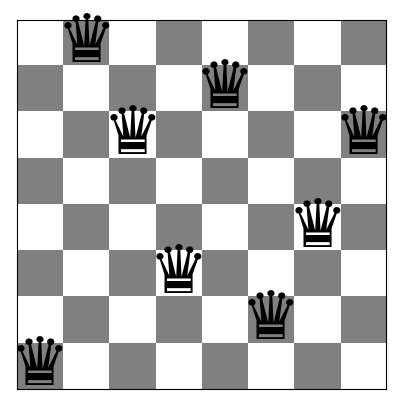

Bàn cờ cuối: [7 0 2 5 1 6 4 2]
Số xung đột cuối: 1
Số bước: 5
Số lần đánh giá: 766
Số lần thử không cải thiện liên tiếp: 560
Có khả năng mắc kẹt: True


In [27]:

def efficient_stochastic_hill_climbing(board, max_failures=None):
    board = np.array(board, dtype=int).copy()
    n = len(board)
    # Ngưỡng thử liên tiếp không cải thiện
    if max_failures is None:
        max_failures = 10 * n * (n - 1)
    steps = 0
    evaluations = 0
    failures = 0
    history = [conflicts(board)]

    while conflicts(board) > 0 and failures < max_failures:
        # Chọn ngẫu nhiên một cột
        col = np.random.randint(n)
        # Chọn một hàng khác hàng hiện tại
        possible_rows = [r for r in range(n) if r != board[col]]
        row = possible_rows[np.random.randint(len(possible_rows))]
        neighbor = board.copy()
        neighbor[col] = row
        neighbor_h = conflicts(neighbor)
        evaluations += 1
        # Chỉ chấp nhận nước đi cải thiện
        if neighbor_h < conflicts(board):
            board = neighbor
            steps += 1
            failures = 0
            history.append(neighbor_h)
        else:
            failures += 1

    final_h = conflicts(board)
    stopped_by_limit = failures >= max_failures and final_h > 0

    return {
        "board": board,
        "conflicts": final_h,
        "steps": steps,
        "evaluations": evaluations,
        "failures": failures,
        "local_optimum": stopped_by_limit,
        "plateau": stopped_by_limit,
        "history": history
    }

# Thử nghiệm với bàn cờ 8 quân hậu
result3 = efficient_stochastic_hill_climbing(random_board(8))
show_board(result3["board"])
print("Bàn cờ cuối:", result3["board"])
print("Số xung đột cuối:", result3["conflicts"])
print("Số bước:", result3["steps"])
print("Số lần đánh giá:", result3["evaluations"])
print("Số lần thử không cải thiện liên tiếp:", result3["failures"])
print("Có khả năng mắc kẹt:", result3["local_optimum"])


Ghi nhận và so sánh kết quả

In [29]:

def compare_hill_climbing(n, trials=100):
    algorithms = {
        "Steepest": steepest_hill_climbing,
        "Inefficient Stochastic": inefficient_stochastic_hill_climbing,
        "Efficient Stochastic": efficient_stochastic_hill_climbing
    }

    results = []

    for name, algorithm in algorithms.items():
        conflicts_list = []
        steps_list = []
        evaluations_list = []
        solved = 0
        stuck = 0

        for _ in range(trials):
            initial_board = random_board(n)
            result = algorithm(initial_board)

            conflicts_list.append(result["conflicts"])
            steps_list.append(result["steps"])
            evaluations_list.append(result["evaluations"])
            if result["conflicts"] == 0:
                solved += 1
            if result["local_optimum"]:
                stuck += 1

        results.append({
            "Algorithm": name,
            "n": n,
            "Trials": trials,
            "Avg final conflicts": np.mean(conflicts_list),
            "Avg steps": np.mean(steps_list),
            "Avg evaluations": np.mean(evaluations_list),
            "Success rate (%)": 100 * solved / trials,
            "Stuck rate (%)": 100 * stuck / trials
        })
    return results

# So sánh với n = 4
results_n4 = compare_hill_climbing(4, trials=100)

# So sánh với n = 8
results_n8 = compare_hill_climbing(8, trials=100)

# Hiển thị bảng kết quả
import pandas as pd

df = pd.DataFrame(results_n4 + results_n8)
display(df.round(2))


,Algorithm,n,Trials,Avg final conflicts,Avg steps,Avg evaluations,Success rate (%),Stuck rate (%)
0,Steepest,4,100,0.64,1.46,29.52,41.0,59.0
1,Inefficient Stochastic,4,100,0.82,1.96,35.52,26.0,74.0
2,Efficient Stochastic,4,100,0.82,1.72,90.04,34.0,66.0
3,Steepest,8,100,1.22,3.42,247.52,12.0,88.0
4,Inefficient Stochastic,8,100,1.36,4.60,313.60,11.0,89.0
5,Efficient Stochastic,8,100,1.31,4.76,555.21,13.0,87.0
